# VQE：调整电路，让能量降低

VQE（变分量子本征求解器）用一个参数化电路准备量子态，再调整参数，使该状态的能量降低。
这里用一个可以手算最低能量的两比特系统，只执行两次 SGD 更新，验证整个流程。

所有计算和图形都使用 qutai 与 Python 标准库，不需要下载数据。

In [3]:
from qutai import Tensor, nn, visualization
from qutai.quantum import CNOT, RY, X, Z, Circuit

## 1. 用观测量描述能量

哈密顿量可以理解为系统的能量规则。本例使用：

$$H=-X_0X_1-\tfrac12 Z_0-\tfrac12 Z_1.$$

`X(0) @ X(1)` 表示分别作用于两个不同量子比特的联合观测量；`+`、`-` 和实数乘法组合出带权的和。
这里的 `@` 表示张量积，两个算符必须作用于不同的比特。

这个系统的理论最低能量是 $-\sqrt{2}$，我们用它作为参照线。


In [4]:
hamiltonian = -(X(0) @ X(1)) - 0.5 * Z(0) - 0.5 * Z(1)
minimum = -1.4142135623730951

print("理论最低能量:", minimum)

理论最低能量: -1.4142135623730951


## 2. 准备一个可训练角度

从 `|00⟩` 开始，先执行 RY，再执行 CNOT，得到：

$$|\psi(\theta)\rangle=\cos(\theta/2)|00\rangle+\sin(\theta/2)|11\rangle.$$

这个状态的能量为 $E(\theta)=-\sin\theta-\cos\theta$，在 $\theta=\pi/4$ 时达到本例的理论最低值。
电路保留原角度 Tensor 的引用，因此每次更新角度后可以直接重新求期望值。


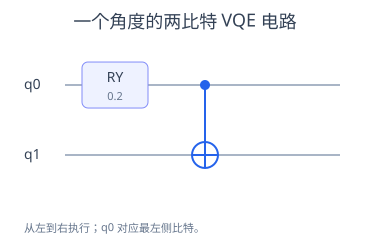

In [5]:
angle = Tensor(0.2, requires_grad=True)
circuit = Circuit(2, [RY(0, angle), CNOT(0, 1)])
optimizer = nn.SGD(circuit, learning_rate=0.2)

visualization.Circuit(circuit, title="一个角度的两比特 VQE 电路")

## 3. 一次模拟读取多个结果

传入单个观测量，得到一个标量；传入观测量列表，得到按列表顺序排列的一维结果。
下面同时读取两个局部 Z 期望值与联合 XX 期望值，三项共享一次电路模拟。

这也说明：观测量可以作为模型的读出特征，也可以组合成一个用于优化的能量。

In [6]:
readout = circuit.expectation([Z(0), Z(1), X(0) @ X(1)])
print("[Z₀, Z₁, X₀X₁] 的期望值:", readout.tolist())

initial_energy = circuit.expectation(hamiltonian).item()
history = [[0, angle.item(), initial_energy]]
print("训练前能量:", initial_energy)

[Z₀, Z₁, X₀X₁] 的期望值: [0.9800665778412417, 0.9800665778412417, 0.19866933079506124]
训练前能量: -1.178735908636303


## 4. 只更新两次

能量本身就是要最小化的目标，不需要额外加 MSE。
`energy.backward()` 把能量梯度传回电路角度，SGD 再更新角度。

两步用于验证求期望、反向传播和参数更新已经接通；不要求两步就达到最低能量。

In [9]:
for step in range(5):
    optimizer.zero_grad()
    energy = circuit.expectation(hamiltonian)
    energy.backward()
    optimizer.step()

    current_energy = circuit.expectation(hamiltonian).item()
    history.append([step, angle.item(), current_energy])
    print(f"step {step}  angle {angle.item():.6f}  energy {current_energy:.8f}")

visualization.Table(history, columns=["更新次数", "角度", "能量"], title="两次更新的结果")

step 0  angle 0.560632  energy -1.37864084
step 1  angle 0.623672  energy -1.39575913
step 2  angle 0.669216  energy -1.40467950
step 3  angle 0.702003  energy -1.40929868
step 4  angle 0.725563  energy -1.41168274


更新次数,角度,能量
0,0.2,-1.178735908636303
0,0.35627944940923606,-1.2859907488475915
1,0.47396169851731706,-1.3461819442378569
0,0.560632148616064,-1.3786408360262374
1,0.6236716426625355,-1.3957591302820629
2,0.6692156654248078,-1.4046795031722377
3,0.7020031589964704,-1.4092986773847822
4,0.7255634967881943,-1.4116827428378973


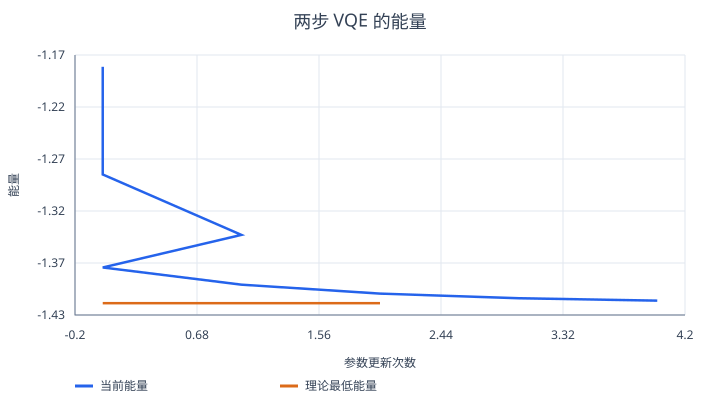

In [10]:
visualization.Plot(title="两步 VQE 的能量", xlabel="参数更新次数", ylabel="能量").line(
    [row[0] for row in history], [row[2] for row in history], label="当前能量"
).line([0, 2], [minimum, minimum], label="理论最低能量")

## 5. 看看训练后的量子态

概率图显示整个两比特系统的联合分布，Bloch 球则只显示指定比特的局部状态。

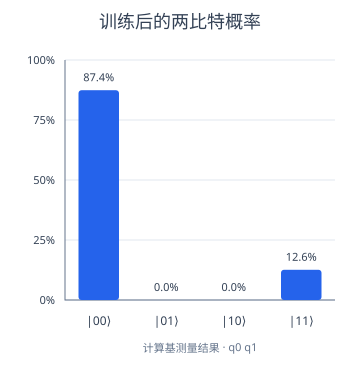

In [11]:
state = circuit.run()
visualization.Probabilities(state, title="训练后的两比特概率")

虽然整个系统保持纯态，但两个比特已经纠缠，单独看 q0 时一般是混合态。
因此它的 Bloch 向量会落在球内。Bloch 球只能描述一个比特的局部状态，不能单独展示两个比特的全部关联。

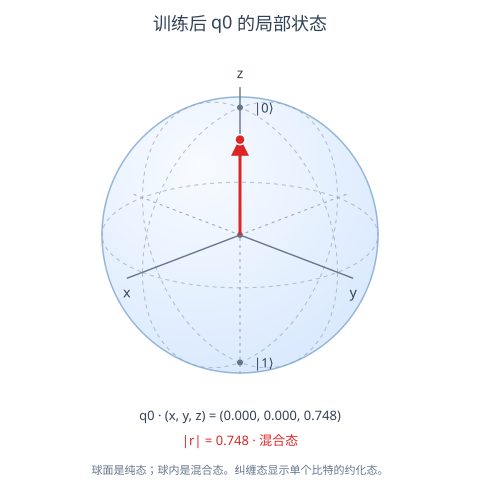

In [12]:
visualization.Bloch(state, wire=0, title="训练后 q0 的局部状态")

本例只展示两比特能量优化，不涉及分子积分或额外量子化学依赖。

原理参考：[PennyLane 的 VQE 介绍](https://pennylane.ai/demos/tutorial_vqe)。
Bloch 球参考：[IBM 的量子态可视化说明](https://quantum.cloud.ibm.com/docs/en/guides/plot-quantum-states)。
